# CS4152 Homework 2 - Simple Python Code

Name: Luqman Khan  
SID : S2024266054
Section :  V1
Submitted to : DR Jameel Ahmad

## Q1 - Concept-Based MLP Training

**(a)** First compute $z^{(1)}=W^{(1)}x+b^{(1)}$ and $a^{(1)}=\mathrm{ReLU}(z^{(1)})$. Next compute $z^{(2)}=W^{(2)}a^{(1)}+b^{(2)}$ and $a^{(2)}=\sigma(z^{(2)})$. Finally, $\hat y=W^{(3)}a^{(2)}+b^{(3)}$ and $L=\frac12(y-\hat y)^2$.

**(b)** Since the output is linear, $\frac{\partial L}{\partial W^{(3)}}=(\hat y-y)(a^{(2)})^T$ and $\frac{\partial L}{\partial b^{(3)}}=\hat y-y$. SGD changes $\theta$ to $\theta-0.1\nabla_\theta L$.

**(c)** The code uses `nn.Sequential`, exact parameters, autograd, and `torch.optim.SGD` on only the output layer.

**Q1 - Forward pass and one SGD update**

In [1]:

import math
import torch
from torch import nn

torch.manual_seed(42)
dtype = torch.float64

model = nn.Sequential(
    nn.Linear(3, 4), nn.ReLU(),
    nn.Linear(4, 3), nn.Sigmoid(),
    nn.Linear(3, 1)
).to(dtype=dtype)


with torch.no_grad():
    model[0].weight.copy_(torch.tensor([
        [0.1, 0.2, -0.3], [0.4, -0.1, 0.2],
        [-0.2, 0.3, 0.1], [0.1, 0.1, -0.1]
    ], dtype=dtype))
    model[0].bias.copy_(torch.tensor([0.1, -0.1, 0.2, 0.0], dtype=dtype))

    model[2].weight.copy_(torch.tensor([
        [0.2, -0.1, 0.3, 0.1],
        [0.1, 0.2, -0.2, 0.3],
        [-0.3, 0.1, 0.2, 0.2]
    ], dtype=dtype))
    model[2].bias.copy_(torch.tensor([0.0, 0.1, -0.1], dtype=dtype))

    model[4].weight.copy_(torch.tensor([[0.5, -0.4, 0.3]], dtype=dtype))
    model[4].bias.copy_(torch.tensor([0.1], dtype=dtype))

x = torch.tensor([[1.0, 0.5, -1.0]], dtype=dtype)
y = torch.tensor([[1.5]], dtype=dtype)


with torch.no_grad():
    z1 = model[0](x)
    a1 = model[1](z1)
    z2 = model[2](a1)
    a2 = model[3](z2)
    y_pred = model[4](a2)
    loss_before = 0.5 * (y - y_pred).square().mean()

for name, value in [('z1', z1), ('a1', a1), ('z2', z2), ('a2', a2)]:
    print(name, value.flatten().tolist())
print(f'Prediction before SGD: {y_pred.item():.8f}')
print(f'Loss before SGD:       {loss_before.item():.8f}')

z1 [0.6, 0.05000000000000002, 0.04999999999999999, 0.25]
a1 [0.6, 0.05000000000000002, 0.04999999999999999, 0.25]
z2 [0.15499999999999997, 0.23500000000000001, -0.215]
a2 [0.538672605206508, 0.5584811124381613, 0.4464560968488817]
Prediction before SGD: 0.27988069
Loss before SGD:       0.74434557


** Q1(b,c) - Only the last layer is trained**

In [2]:

for layer in (model[0], model[2]):
    for parameter in layer.parameters():
        parameter.requires_grad = False

optimizer = torch.optim.SGD(model[4].parameters(), lr=0.1)
optimizer.zero_grad()
loss = 0.5 * (y - model(x)).square().mean()
loss.backward()

print('dL/dW3:', model[4].weight.grad.flatten().tolist())
print('dL/db3:', model[4].bias.grad.item())
optimizer.step()

with torch.no_grad():
    new_prediction = model(x)
    new_loss = 0.5 * (y - new_prediction).square().mean()
print('New W3:', model[4].weight.flatten().tolist())
print('New b3:', model[4].bias.item())
print(f'Prediction after SGD:  {new_prediction.item():.8f}')
print(f'Loss after SGD:        {new_loss.item():.8f}')

# Q1(d) - Suggested standard deviations for fresh initialization
print(f'He std for W1:     {math.sqrt(2 / 3):.6f}')
print(f'Xavier std for W2: {math.sqrt(2 / (4 + 3)):.6f}')

dL/dW3: [-0.6572448491674303, -0.6814135914087569, -0.5447297063136001]
dL/db3: -1.220119313317346
New W3: [0.565724484916743, -0.3318586408591243, 0.35447297063136]
New b3: 0.2220119313317346
Prediction after SGD:  0.49967205
Loss after SGD:        0.50032800
He std for W1:     0.816497
Xavier std for W2: 0.534522


**(d) Initialization:** Use He initialization for layer 1 (ReLU), with standard deviation $\sqrt{2/3}=0.8165$. Use Xavier initialization for layer 2 (Sigmoid), with standard deviation $\sqrt{2/(4+3)}=0.5345$. If every weight starts at zero, neurons in the same layer receive the same gradient, so they cannot learn different features (symmetry is not broken).

## Q2 - California Housing Regression

**(a) Complete pipeline:** The data is split **70% training / 15% validation / 15% test**. `StandardScaler` is fitted on training data only; fitting on validation or test data would leak their statistics into training. The model has three hidden layers (`64, 32, 16`) with BatchNorm, ReLU and Dropout, a linear output, and He initialization for the hidden layers. It trains in batches of 128 with AdamW, a cosine learning-rate scheduler and early stopping (patience 15). The best weights are restored.

**(b) Ablation:** The same network is trained four times: no additional regularization, AdamW weight decay, Dropout, and both. The notebook reports train MSE, validation MSE, their difference, and test $R^2$. Here the ablation label **L2** refers to AdamW's *decoupled weight decay*; see Q6(b)(iii) for the distinction. BatchNorm remains enabled in all runs as required by Q2(a).

**(c) Permutation importance:** Shuffle one test feature at a time and measure the increase in test MSE. Larger increase means that feature matters more to this trained model. **Integrated Gradients** is an alternative that gives attributions for individual predictions (rather than only global test-set importance).

*The numerical results in Q2 appear only when you actually run the code against the California Housing dataset.*

** Q2 - California Housing regression, ablation, and feature importance**

In [3]:

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

** Three hidden layers, each with BatchNorm, ReLU and optional Dropout.**

In [4]:

class HousingModel(nn.Module):
    def __init__(self, dropout_rate=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(8, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(32, 16), nn.BatchNorm1d(16), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(16, 1)
        )
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')
                nn.init.zeros_(layer.bias)

        nn.init.xavier_normal_(self.net[-1].weight)

    def forward(self, x):
        return self.net(x).squeeze(1)


def predict(model, X):
    model.eval()
    with torch.no_grad():
        out = []
        for start in range(0, len(X), 4096):
            batch = torch.tensor(X[start:start + 4096], dtype=torch.float32, device=DEVICE)
            out.append(model(batch).cpu().numpy())
    return np.concatenate(out)


def mse(model, X, y):
    return mean_squared_error(y, predict(model, X))

In [5]:
def train_model(X_train, y_train, X_val, y_val, dropout, decay,
                max_epochs=100, patience=15):
    set_seed()
    model = HousingModel(dropout).to(DEVICE)
    dataset = TensorDataset(torch.tensor(X_train), torch.tensor(y_train))
    loader = DataLoader(dataset, batch_size=128, shuffle=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max_epochs, eta_min=0.00001
    )

    best_mse = float('inf')
    best_weights = copy.deepcopy(model.state_dict())
    bad_epochs = 0
    train_curve, val_curve = [], []
    best_epoch = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(xb), yb)
            loss.backward()
            optimizer.step()
        scheduler.step()

        train_error = mse(model, X_train, y_train)
        val_error = mse(model, X_val, y_val)
        train_curve.append(train_error)
        val_curve.append(val_error)

        if val_error < best_mse - 1e-7:
            best_mse = val_error
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break

    model.load_state_dict(best_weights)
    return model, train_curve, val_curve, best_epoch

Train / Validation / Test: 14448 3096 3096
Device: cpu

Training: No regularization
Best epoch: 48 Validation MSE: 0.2969

Training: L2 only
Best epoch: 48 Validation MSE: 0.30006

Training: Dropout only
Best epoch: 36 Validation MSE: 0.33311

Training: L2 + Dropout
Best epoch: 36 Validation MSE: 0.33469
Test MSE: 0.34157
Test MAE: 0.408791
Test R2:  0.739361

Ablation results:
             Model  Best epoch  Train MSE  Validation MSE  Overfitting gap  Test R2
No regularization          48    0.26938         0.29690          0.02752  0.77697
          L2 only          48    0.27609         0.30006          0.02397  0.77542
     Dropout only          36    0.33204         0.33311          0.00106  0.74046
     L2 + Dropout          36    0.33352         0.33469          0.00117  0.73936


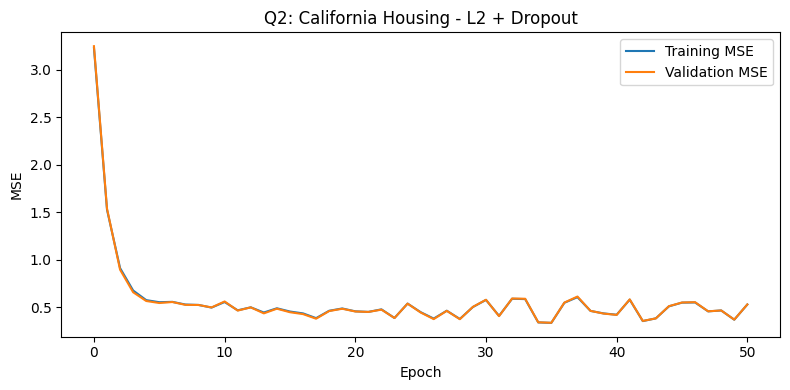


Permutation importance ranking:
    Feature  Increase in MSE
    MedInc         1.074500
  Latitude         1.005612
 Longitude         0.921343
  AveOccup         0.186372
  HouseAge         0.076703
  AveRooms         0.043593
 AveBedrms         0.024312
Population         0.012120


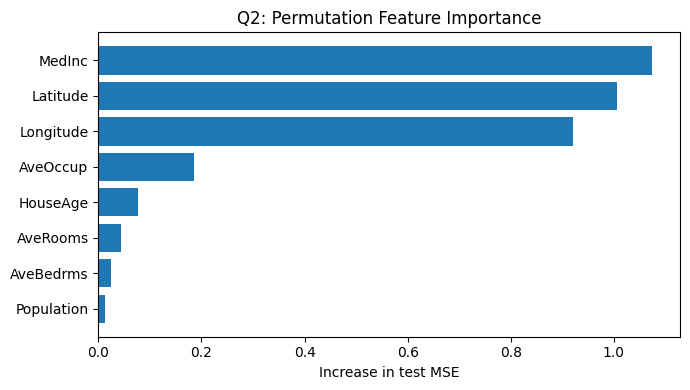

In [6]:
def run_housing(max_epochs=100, patience=15):
    set_seed()
    data = fetch_california_housing()
    X = data.data.astype(np.float32)
    y = data.target.astype(np.float32)


    X_trainval, X_test, y_trainval, y_test = train_test_split(
        X, y, test_size=0.15, random_state=SEED
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval, test_size=0.15 / 0.85, random_state=SEED
    )
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train).astype(np.float32)
    X_val = scaler.transform(X_val).astype(np.float32)
    X_test = scaler.transform(X_test).astype(np.float32)
    print('Train / Validation / Test:', len(y_train), len(y_val), len(y_test))
    print('Device:', DEVICE)


    experiments = [
        ('No regularization', 0.00, 0.000),
        ('L2 only',          0.00, 0.001),
        ('Dropout only',     0.20, 0.000),
        ('L2 + Dropout',     0.20, 0.001)
    ]
    rows = []
    selected_model = None
    selected_curves = None

    for name, dropout, decay in experiments:
        print('\nTraining:', name)
        model, train_curve, val_curve, epoch = train_model(
            X_train, y_train, X_val, y_val, dropout, decay, max_epochs, patience
        )
        tr_mse = mse(model, X_train, y_train)
        va_mse = mse(model, X_val, y_val)
        test_pred = predict(model, X_test)
        test_r2 = r2_score(y_test, test_pred)
        rows.append([name, epoch, tr_mse, va_mse, va_mse - tr_mse, test_r2])
        print('Best epoch:', epoch, 'Validation MSE:', round(va_mse, 5))

        if name == 'L2 + Dropout':
            selected_model = model
            selected_curves = (train_curve, val_curve)
            print('Test MSE:', round(mean_squared_error(y_test, test_pred), 6))
            print('Test MAE:', round(mean_absolute_error(y_test, test_pred), 6))
            print('Test R2: ', round(test_r2, 6))

    # Q2(b) - Ablation study
    table = pd.DataFrame(rows, columns=[
        'Model', 'Best epoch', 'Train MSE', 'Validation MSE', 'Overfitting gap', 'Test R2'
    ])
    print('\nAblation results:\n', table.round(5).to_string(index=False))
    table.to_csv('Q2_ablation_results.csv', index=False)

    # Q2(a) - Training / validation loss plot for the main model
    train_curve, val_curve = selected_curves
    plt.figure(figsize=(8, 4))
    plt.plot(train_curve, label='Training MSE')
    plt.plot(val_curve, label='Validation MSE')
    plt.xlabel('Epoch')
    plt.ylabel('MSE')
    plt.title('Q2: California Housing - L2 + Dropout')
    plt.legend()
    plt.tight_layout()
    plt.savefig('Q2_loss_plot.png', dpi=150)
    plt.show()

    # Q2(c) - Permutation importance: change one feature at a time.
    baseline = mse(selected_model, X_test, y_test)
    generator = np.random.default_rng(SEED)
    importance = []
    for col, feature in enumerate(data.feature_names):
        changes = []
        for repeat in range(5):
            shuffled = X_test.copy()
            shuffled[:, col] = generator.permutation(shuffled[:, col])
            changes.append(mse(selected_model, shuffled, y_test) - baseline)
        importance.append([feature, np.mean(changes)])

    importance_table = pd.DataFrame(importance, columns=['Feature', 'Increase in MSE'])
    importance_table = importance_table.sort_values('Increase in MSE', ascending=False)
    print('\nPermutation importance ranking:\n', importance_table.to_string(index=False))
    importance_table.to_csv('Q2_feature_importance.csv', index=False)

    plt.figure(figsize=(7, 4))
    plt.barh(importance_table['Feature'][::-1], importance_table['Increase in MSE'][::-1])
    plt.xlabel('Increase in test MSE')
    plt.title('Q2: Permutation Feature Importance')
    plt.tight_layout()
    plt.savefig('Q2_importance_plot.png', dpi=150)
    plt.show()


if __name__ == '__main__':
    run_housing()

## Q3 - Credit-Card Fraud Detection

**(a) Imbalanced classes:** The original dataset has $N=284{,}807$, with $N_0=284{,}315$ normal transactions and $N_1=492$ fraud transactions.

- **SMOTE** creates synthetic minority-class training examples. Apply it only to a training fold, never to validation/test rows.
- **Class-weighted BCE** makes fraud errors more costly: $L=-[w_1y\log p+w_0(1-y)\log(1-p)]$.
- **Decision-threshold tuning** changes the cutoff for predicting fraud instead of always using 0.5. Tune on validation data only.
- Balanced weights: $w_c=N/(2N_c)$. PyTorch `BCEWithLogitsLoss(pos_weight=...)` uses the ratio $N_0/N_1$, calculated separately inside each training fold.
- **Focal loss:** $FL=-\alpha_t(1-p_t)^\gamma\log(p_t)$, where $p_t=p$ for a positive example and $p_t=1-p$ for a negative one. $\alpha$ handles class weighting, and $\gamma$ down-weights easy examples.

**(c) Threshold comparison:** Accuracy $=(TP+TN)/N$, precision $=TP/(TP+FP)$, recall $=TP/(TP+FN)$, $F_1=2TP/(2TP+FP+FN)$, $F_2=5TP/(5TP+4FN+FP)$, and $FPR=FP/(FP+TN)$. Cost $=500FN+5FP$.

**Q3(a) class weights and Q3(c) threshold comparison**

In [7]:

import pandas as pd

normal, fraud = 284315, 492
N = normal + fraud
print('Balanced weight for normal:', round(N / (2 * normal), 6))
print('Balanced weight for fraud: ', round(N / (2 * fraud), 6))
print('PyTorch pos_weight:        ', round(normal / fraud, 6))

rows = []
for name, TP, FP, FN, TN in [
    ('A', 450, 800, 42, 283515),
    ('B', 430, 300, 62, 284015)
]:
    accuracy = (TP + TN) / (TP + FP + FN + TN)
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1 = 2 * TP / (2 * TP + FP + FN)
    f2 = 5 * TP / (5 * TP + 4 * FN + FP)
    fpr = FP / (FP + TN)
    cost = 500 * FN + 5 * FP
    rows.append([name, accuracy, precision, recall, f1, f2, fpr, cost])

result = pd.DataFrame(rows, columns=[
    'Threshold', 'Accuracy', 'Precision', 'Recall', 'F1', 'F2', 'FPR', 'Cost ($)'
])
print('\nQ3(c) threshold comparison:')
print(result.round(6).to_string(index=False))
print('\nAlways predict normal accuracy:', round(normal / N, 6))
print('Cheaper threshold:', result.loc[result['Cost ($)'].idxmin(), 'Threshold'])

Balanced weight for normal: 0.500865
Balanced weight for fraud:  289.438008
PyTorch pos_weight:         577.876016

Q3(c) threshold comparison:
Threshold  Accuracy  Precision   Recall       F1       F2      FPR  Cost ($)
        A  0.997044   0.360000 0.914634 0.516648 0.699192 0.002814     25000
        B  0.998729   0.589041 0.873984 0.703764 0.796887 0.001055     32500

Always predict normal accuracy: 0.998273
Cheaper threshold: A


### Q3(b) - Train a Fraud-Detection MLP

Get the original CSV from [Kaggle - Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). **Upload `creditcard.csv` using the next cell.** The full dataset contains 284,807 rows. Do not replace it with a generated or shortened sample for your final results.

The code uses:
- **Stratified 5-fold cross-validation**, so each fold contains some fraud cases.
- Within each fold, a stratified validation split from the fold's training portion.
- `StandardScaler` trained on only the fold's training subset.
- MLP with a **logit output**, class-weighted BCE and **AdamW**.
- The epoch with the **best validation AUPRC** and a threshold chosen to **maximize validation F1**.
- Held-out test-fold AUROC, AUPRC and F1, then **mean ± sample standard deviation** over five folds.

The test fold must not affect the scaler, early stopping or threshold: otherwise the scores would be biased.

In [8]:
# Skip uploading if the file is already present in Colab.
import os

if not os.path.exists('creditcard.csv'):
    from google.colab import files
    print('Select the file named creditcard.csv')
    files.upload()
else:
    print('Found creditcard.csv')

Select the file named creditcard.csv


Saving creditcard.csv to creditcard.csv


# Q3 - Credit-card fraud classification (5-fold stratified cross-validation)

Download creditcard.csv from: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
In Colab, upload the CSV using the Files sidebar or the upload cell in the notebook.

In [9]:

import copy
import os
import random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, f1_score)

SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [10]:
class FraudModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(30, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(1)


def get_probabilities(model, X):
    model.eval()
    predictions = []
    with torch.no_grad():
        for start in range(0, len(X), 8192):
            xb = torch.tensor(X[start:start + 8192], dtype=torch.float32, device=DEVICE)
            predictions.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(predictions)


def best_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)

    f1_values = 2 * precision[:-1] * recall[:-1] / (
        precision[:-1] + recall[:-1] + 1e-12
    )
    return float(thresholds[np.argmax(f1_values)])

In [11]:
def run_fraud(csv_file='creditcard.csv', max_epochs=25, patience=5):
    if not os.path.exists(csv_file):
        raise FileNotFoundError('Upload creditcard.csv to Colab before running Q3.')

    df = pd.read_csv(csv_file)
    features = ['Time'] + [f'V{i}' for i in range(1, 29)] + ['Amount']
    missing = set(features + ['Class']) - set(df.columns)
    if missing:
        raise ValueError(f'The CSV is missing columns: {missing}')
    X = df[features].to_numpy(dtype=np.float32)
    y = df['Class'].to_numpy(dtype=np.int64)
    print('Transactions:', len(y), 'Fraud:', sum(y), 'Normal:', len(y) - sum(y))

    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    results = []

    for fold, (trainval_idx, test_idx) in enumerate(folds.split(X, y), 1):

        train_idx, val_idx = train_test_split(
            trainval_idx, test_size=0.20, stratify=y[trainval_idx],
            random_state=SEED + fold
        )

        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[train_idx]).astype(np.float32)
        X_val = scaler.transform(X[val_idx]).astype(np.float32)
        X_test = scaler.transform(X[test_idx]).astype(np.float32)
        y_train = y[train_idx]
        y_val = y[val_idx]
        y_test = y[test_idx]

        set_seed(SEED + fold)
        model = FraudModel().to(DEVICE)
        normal = int((y_train == 0).sum())
        fraud = int((y_train == 1).sum())
        pos_weight = torch.tensor(normal / fraud, dtype=torch.float32, device=DEVICE)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
        train_data = TensorDataset(torch.tensor(X_train), torch.tensor(y_train, dtype=torch.float32))
        loader = DataLoader(train_data, batch_size=1024, shuffle=True)

        best_ap = -1
        best_epoch = 0
        best_weights = copy.deepcopy(model.state_dict())
        bad_epochs = 0

        for epoch in range(1, max_epochs + 1):
            model.train()
            for xb, yb in loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                optimizer.zero_grad()
                loss = loss_fn(model(xb), yb)
                loss.backward()
                optimizer.step()

            val_prob = get_probabilities(model, X_val)
            val_ap = average_precision_score(y_val, val_prob)
            if val_ap > best_ap + 1e-6:
                best_ap = val_ap
                best_epoch = epoch
                best_weights = copy.deepcopy(model.state_dict())
                bad_epochs = 0
            else:
                bad_epochs += 1
                if bad_epochs >= patience:
                    break

        # Restore the epoch with the highest validation AUPRC.
        model.load_state_dict(best_weights)
        val_prob = get_probabilities(model, X_val)
        threshold = best_threshold(y_val, val_prob)
        test_prob = get_probabilities(model, X_test)
        scores = {
            'Fold': fold,
            'Best epoch': best_epoch,
            'Threshold': threshold,
            'AUROC': roc_auc_score(y_test, test_prob),
            'AUPRC': average_precision_score(y_test, test_prob),
            'F1': f1_score(y_test, test_prob >= threshold, zero_division=0)
        }
        results.append(scores)
        print('Fold', fold, 'results:', {k: round(v, 5) for k, v in scores.items()})

    result_table = pd.DataFrame(results)
    print('\nAll five folds:\n', result_table.round(5).to_string(index=False))
    result_table.to_csv('Q3_five_fold_results.csv', index=False)
    for metric in ['AUROC', 'AUPRC', 'F1']:
        print(f'{metric}: {result_table[metric].mean():.4f} +/- {result_table[metric].std(ddof=1):.4f}')
    return result_table


if __name__ == '__main__':
    run_fraud()

Transactions: 284807 Fraud: 492 Normal: 284315
Fold 1 results: {'Fold': 1, 'Best epoch': 1, 'Threshold': 0.95546, 'AUROC': np.float64(0.96495), 'AUPRC': np.float64(0.70058), 'F1': 0.78351}
Fold 2 results: {'Fold': 2, 'Best epoch': 1, 'Threshold': 0.97441, 'AUROC': np.float64(0.97501), 'AUPRC': np.float64(0.76803), 'F1': 0.83505}
Fold 3 results: {'Fold': 3, 'Best epoch': 4, 'Threshold': 0.99883, 'AUROC': np.float64(0.98405), 'AUPRC': np.float64(0.76087), 'F1': 0.84324}
Fold 4 results: {'Fold': 4, 'Best epoch': 5, 'Threshold': 0.99946, 'AUROC': np.float64(0.97029), 'AUPRC': np.float64(0.7666), 'F1': 0.80899}
Fold 5 results: {'Fold': 5, 'Best epoch': 18, 'Threshold': 0.9999, 'AUROC': np.float64(0.96687), 'AUPRC': np.float64(0.74344), 'F1': 0.80829}

All five folds:
  Fold  Best epoch  Threshold   AUROC   AUPRC      F1
    1           1    0.95546 0.96495 0.70058 0.78351
    2           1    0.97441 0.97501 0.76803 0.83505
    3           4    0.99883 0.98405 0.76087 0.84324
    4         

## Q4 - Backpropagation and Gradient Descent

**(a) Derivation:** Let $z_1=W_1x+b_1$, $a_1=\mathrm{ReLU}(z_1)$, $z_2=w_2^Ta_1+b_2$, $\hat y=\sigma(z_2)$ and binary cross-entropy $L=-[y\ln\hat y+(1-y)\ln(1-\hat y)]$.

1. $\frac{\partial L}{\partial\hat y}=-y/\hat y+(1-y)/(1-\hat y)$.
2. $\frac{\partial\hat y}{\partial z_2}=\hat y(1-\hat y)$.
3. Chain rule gives $\boxed{\frac{\partial L}{\partial z_2}=\hat y-y}$.
4. Therefore $\boxed{\frac{\partial L}{\partial w_2}=(\hat y-y)a_1}$.
5. With $r=\mathbf 1[z_1>0]$, $\boxed{\frac{\partial L}{\partial W_1}=((\hat y-y)w_2\odot r)x^T}$.

Sigmoid derivatives are at most $0.25$ and can become tiny when saturated. Multiplying many such derivatives makes earlier-layer gradients vanish. ReLU has derivative 1 for positive inputs, which reduces this effect (although inactive ReLU units still have derivative 0).

**(b)** For $L(\theta)=\theta_1^2+10\theta_2^2$, the gradient is $(2\theta_1,20\theta_2)$ and the Hessian is $\mathrm{diag}(2,20)$. Convergence requires $0<\eta<2/20=0.1$. At $\eta=0.1$, $\theta_2$ oscillates instead of converging. The Hessian condition number is $20/2=10$.

**(c)** Full-batch GD has 1 update per epoch (exact gradient but high update cost); SGD has $N$ updates (low cost but noisy); mini-batch GD has $\lceil N/B\rceil$ updates (intermediate cost/noise). SGD's noise can help it move away from saddle points where the full gradient is zero.

Q4, Q5 and Q6 - numerical parts of the homework

In [12]:

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Q4(b): Batch gradient descent, L = theta1^2 + 10*theta2^2
print('\nQ4(b) - Gradient descent')
theta1, theta2 = 3.0, 1.0
rows = [[0, theta1, theta2, theta1**2 + 10*theta2**2]]
for step in range(1, 4):
    grad1, grad2 = 2*theta1, 20*theta2
    theta1 -= 0.1*grad1
    theta2 -= 0.1*grad2
    rows.append([step, theta1, theta2, theta1**2 + 10*theta2**2])
print(pd.DataFrame(rows, columns=['Step', 'theta1', 'theta2', 'Loss']).round(4).to_string(index=False))
print('Hessian = diag(2, 20), condition number = 20/2 = 10')
print('Convergence requires 0 < learning rate < 0.1 (0.1 is the boundary).')

# Q4(c): Number of updates for N=1000, batch size B=32
print('\nQ4(c) - Batches')
N, B = 1000, 32
print('Full-batch updates per epoch:', 1)
print('SGD updates per epoch:', N)
print('Mini-batch updates per epoch:', math.ceil(N/B))
print('Last mini-batch size:', N % B if N % B else B)


Q4(b) - Gradient descent
 Step  theta1  theta2    Loss
    0   3.000     1.0 19.0000
    1   2.400    -1.0 15.7600
    2   1.920     1.0 13.6864
    3   1.536    -1.0 12.3593
Hessian = diag(2, 20), condition number = 20/2 = 10
Convergence requires 0 < learning rate < 0.1 (0.1 is the boundary).

Q4(c) - Batches
Full-batch updates per epoch: 1
SGD updates per epoch: 1000
Mini-batch updates per epoch: 32
Last mini-batch size: 8


## Q5 - Momentum, RMSProp, Adam and Scheduling

For each optimizer, the table uses the **gradient at the current (pre-update) parameter value**.

**(a) Momentum** uses $g_t=2\theta_{t-1}$, $v_t=0.9v_{t-1}+0.1g_t$, then $\theta_t=\theta_{t-1}-0.1v_t$. The parameter $\beta=0.9$ smooths successive gradients and carries past direction forward.

**(b) RMSProp:** $s_t=0.9s_{t-1}+0.1g_t^2$, $\theta_t=\theta_{t-1}-0.01g_t/(\sqrt{s_t}+10^{-8})$. It reduces the step along parameters with consistently large gradients, helping with unequal curvatures.

**(c) Adam:** $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$; $v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$. Bias corrections are $\hat m_t=m_t/(1-\beta_1^t)$ and $\hat v_t=v_t/(1-\beta_2^t)$. Update $\theta_t=\theta_{t-1}-\eta\hat m_t/(\sqrt{\hat v_t}+\epsilon)$. Bias correction prevents the zero-initialized averages from being too small early on.

**(d) Schedule:** epochs 1-5 use $\eta_e=0.1e/5$; epochs 6-100 use $\eta_e=10^{-4}+\frac12(0.1-10^{-4})[1+\cos(\pi(e-5)/95)]$. Warmup avoids very large initial updates, especially for Adam with large batches.

# Q5(a): Momentum

In [13]:

print('\nQ5(a) - Momentum')
theta, v = 5.0, 0.0
rows = []
for step in range(1, 5):
    grad = 2*theta
    v = 0.9*v + 0.1*grad
    theta -= 0.1*v
    rows.append([step, grad, v, theta, theta**2])
print(pd.DataFrame(rows, columns=['Step', 'Gradient', 'v', 'theta', 'Loss']).round(4).to_string(index=False))

# Q5(b): RMSProp
print('\nQ5(b) - RMSProp')
theta, s = 2.0, 0.0
rows = []
for step in range(1, 4):
    grad = 2*theta
    s = 0.9*s + 0.1*grad**2
    change = 0.01*grad/(math.sqrt(s) + 1e-8)
    theta -= change
    rows.append([step, grad, s, change, theta])
print(pd.DataFrame(rows, columns=['Step', 'Gradient', 's', 'Step size', 'theta']).round(4).to_string(index=False))




Q5(a) - Momentum
 Step  Gradient      v  theta    Loss
    1   10.0000 1.0000 4.9000 24.0100
    2    9.8000 1.8800 4.7120 22.2029
    3    9.4240 2.6344 4.4486 19.7897
    4    8.8971 3.2607 4.1225 16.9949

Q5(b) - RMSProp
 Step  Gradient      s  Step size  theta
    1    4.0000 1.6000     0.0316 1.9684
    2    3.9368 2.9898     0.0228 1.9456
    3    3.8912 4.2050     0.0190 1.9266


 Q5(c): Adam, including bias correction


Q5(c) - Adam
 Step  Gradient      m      v   m_hat   v_hat  Update  theta
    1   -6.0000 -0.600 0.0360 -6.0000 36.0000 -0.1000 0.1000
    2   -5.8000 -1.120 0.0696 -5.8947 34.8194 -0.0999 0.1999
    3   -5.6002 -1.568 0.1009 -5.7861 33.6659 -0.0997 0.2996

Q5(d) - Learning rate schedule
 Epoch  Learning rate
     1       0.020000
     5       0.100000
    30       0.083880
    55       0.045925
    80       0.010632
   100       0.000100


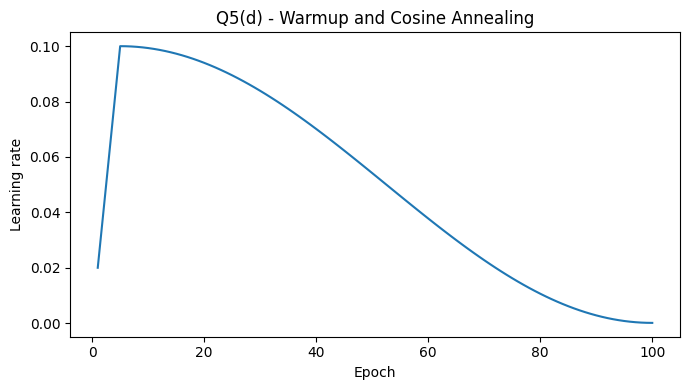

In [14]:

print('\nQ5(c) - Adam')
theta, m, v = 0.0, 0.0, 0.0
rows = []
for step in range(1, 4):
    grad = 2*(theta - 3)
    m = 0.9*m + 0.1*grad
    v = 0.999*v + 0.001*grad**2
    m_corrected = m/(1 - 0.9**step)
    v_corrected = v/(1 - 0.999**step)
    change = 0.1*m_corrected/(math.sqrt(v_corrected) + 1e-8)
    theta -= change
    rows.append([step, grad, m, v, m_corrected, v_corrected, change, theta])
print(pd.DataFrame(rows, columns=[
    'Step', 'Gradient', 'm', 'v', 'm_hat', 'v_hat', 'Update', 'theta'
]).round(4).to_string(index=False))

# Q5(d): Warmup for 5 epochs, then cosine decay until epoch 100
print('\nQ5(d) - Learning rate schedule')
def learning_rate(epoch):
    if epoch <= 5:
        return 0.1 * epoch / 5
    return 0.0001 + 0.5*(0.1 - 0.0001)*(1 + math.cos(math.pi*(epoch - 5)/95))

chosen = [1, 5, 30, 55, 80, 100]
print(pd.DataFrame([(e, learning_rate(e)) for e in chosen],
                   columns=['Epoch', 'Learning rate']).round(6).to_string(index=False))
plt.figure(figsize=(7, 4))
plt.plot(range(1, 101), [learning_rate(e) for e in range(1, 101)])
plt.xlabel('Epoch')
plt.ylabel('Learning rate')
plt.title('Q5(d) - Warmup and Cosine Annealing')
plt.tight_layout()
plt.savefig('Q5_learning_rate.png', dpi=150)
plt.show()

## Q6 - Regularization, Early Stopping and Generalization

**(a) Inverted Dropout:** Let $m_i\sim\mathrm{Bernoulli}(1-p)$ and $\tilde a_i=m_ia_i/(1-p)$. Then $E[\tilde a_i]=a_i E[m_i]/(1-p)=a_i$, which is the inference-time activation. The numeric result is computed below.

**(b)(i) Ridge derivation:** Minimize $J(w)=\frac1N\|y-Xw\|_2^2+\lambda\|w\|_2^2$. Differentiate: $\nabla J(w)=\frac{2}{N}X^T(Xw-y)+2\lambda w$. Setting this to zero gives $(X^TX+N\lambda I)w=X^Ty$; therefore $\boxed{w^*=(X^TX+N\lambda I)^{-1}X^Ty}$, assuming this inverse exists.

**(b)(ii)** The L2 step is $w\leftarrow w-\eta(g+2\lambda w)$. The L1 subgradient step is $w\leftarrow w-\eta(g+\lambda\,\mathrm{sign}(w))$, choosing 0 as the subgradient when $w_i=0$. L1 applies a constant shrinkage magnitude, driving small values toward zero. **One subgradient step does not necessarily produce an exact zero**; the optional proximal L1 example shows exact zeros through soft thresholding.

**(b)(iii)** Coupled L2 adds $2\lambda w$ into the gradient that Adam then rescales using its adaptive moments. **AdamW** applies weight decay separately from the gradient update, so the decay is not distorted by Adam's adaptive normalization.

**(c) Bias-variance:** With $y=f(x)+\epsilon$, $E[\epsilon]=0$ and $\mathrm{Var}(\epsilon)=\sigma_\epsilon^2$, write $y-\hat f=(f-E\hat f)+(E\hat f-\hat f)+\epsilon$. Squaring and taking expectations cancels the zero-mean cross terms and gives $\boxed{E[(y-\hat f)^2]=\mathrm{Bias}^2+\mathrm{Var}+\sigma_\epsilon^2}$. Early stopping limits how closely a network can fit training data, acting like a form of regularization; for some linear gradient-descent settings it behaves similarly to L2 shrinkage.

**(d) Complexity:** Calculate $\text{gap}=\text{validation MSE}-\text{training MSE}$ for each depth. Depths 1-2 underfit, depth 4 has the best validation error, and depths 5-6 overfit. Double descent means test error can rise and *then fall again* as a model becomes highly overparameterized, so it need not always form a single U-shaped curve.


Q6(a) - Inverted dropout
Original: [0.8 1.2 0.  0.5 2.  0.3]
Dropout result: [1.2  0.   0.   0.75 0.   0.45]
Expected dropout result: same as original a (because E[mask]/(1-p) = 1)

Q6(b) - L2 and L1 updates
 Original w  Data gradient  L2 updated  L1 updated
       0.80            0.2       0.700        0.73
      -0.05            0.1      -0.055       -0.01
       0.00           -0.3       0.030        0.03
      -1.20           -0.4      -1.040       -1.11
Extra: proximal L1 (soft threshold): [ 0.73 -0.01  0.   -1.11]

Q6(d) - Model complexity
 Depth  Train MSE  Val MSE  Gap
     1       0.92     0.95 0.03
     2       0.55     0.60 0.05
     3       0.31     0.38 0.07
     4       0.18     0.36 0.18
     5       0.07     0.49 0.42
     6       0.02     0.71 0.69
Best depth (smallest validation MSE): 4


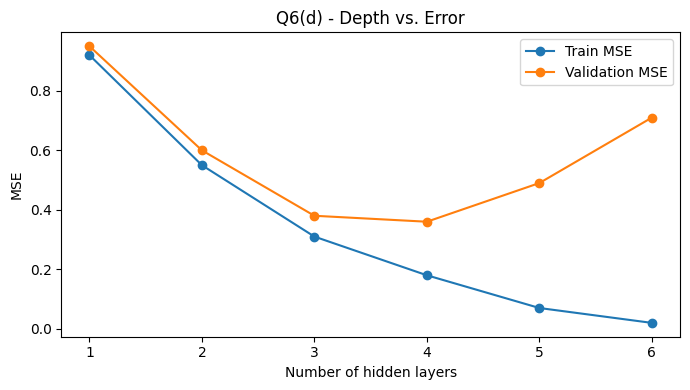

In [15]:
# Q6(a): Inverted dropout
print('\nQ6(a) - Inverted dropout')
a = np.array([0.8, 1.2, 0.0, 0.5, 2.0, 0.3])
mask = np.array([1, 0, 1, 1, 0, 1])
p = 1/3
out = a * mask / (1-p)
print('Original:', a)
print('Dropout result:', out)
print('Expected dropout result: same as original a (because E[mask]/(1-p) = 1)')

# Q6(b): L2 gradient and L1 subgradient steps
print('\nQ6(b) - L2 and L1 updates')
w = np.array([0.8, -0.05, 0.0, -1.2])
g = np.array([0.2, 0.1, -0.3, -0.4])
eta, lam = 0.1, 0.5
w_l2 = w - eta*(g + 2*lam*w)
subgradient = np.sign(w)
w_l1 = w - eta*(g + lam*subgradient)
print(pd.DataFrame({'Original w': w, 'Data gradient': g,
                    'L2 updated': w_l2, 'L1 updated': w_l1}).round(4).to_string(index=False))
# Proximal L1 gives exactly zero for some small coefficients.
temp = w - eta*g
w_prox = np.sign(temp)*np.maximum(np.abs(temp)-eta*lam, 0)
print('Extra: proximal L1 (soft threshold):', np.round(w_prox, 4))

# Q6(d): Generalization gaps
print('\nQ6(d) - Model complexity')
train_mse = np.array([0.92, 0.55, 0.31, 0.18, 0.07, 0.02])
val_mse = np.array([0.95, 0.60, 0.38, 0.36, 0.49, 0.71])
complexity = pd.DataFrame({'Depth': [1, 2, 3, 4, 5, 6],
                           'Train MSE': train_mse, 'Val MSE': val_mse,
                           'Gap': val_mse - train_mse})
print(complexity.round(4).to_string(index=False))
print('Best depth (smallest validation MSE):', int(complexity.loc[complexity['Val MSE'].idxmin(), 'Depth']))
plt.figure(figsize=(7, 4))
plt.plot(complexity['Depth'], train_mse, 'o-', label='Train MSE')
plt.plot(complexity['Depth'], val_mse, 'o-', label='Validation MSE')
plt.xlabel('Number of hidden layers')
plt.ylabel('MSE')
plt.title('Q6(d) - Depth vs. Error')
plt.legend()
plt.tight_layout()
plt.savefig('Q6_model_complexity.png', dpi=150)
plt.show()